Week 7: Model Comparison

To improve the models, several new features that could have a stronger influence on home prices, including bed-to-bathroom ratio, property age (in years), school district information, and median price per square foot by ZIP code were added. The Zip code median price per square foot was calculated using the most recent twelve months of housing data to better reflect current local market conditions. After adding these features, the Linear Regression, Decision Tree, and Random Forest modesl were retrained and their results were compared with the original models to see whether the additional information improved prediction accuracy. The most recent three months of data was used as the validation set to evaluate how well the models performed on newer housing market data. In addition, Gradient Boosting methods, including XGBoost and LightGBM were explored to see if they could provide better predictions. Finally, some basic hyperparameter tuning by adjusting tree depth, learning rate, and the number of estimators were performed to find better-performing model settings while reducing the risk of overfitting.  

In [1]:
from pathlib import Path
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import category_encoders as ce
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, median_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import geopandas as gpd
from IPython.display import display, Markdown
import sklearn
import xgboost
from xgboost import XGBRegressor
from scipy.stats import randint
from sklearn.compose import TransformedTargetRegressor
import lightgbm as lgb


In [2]:
path_dir = Path("raw")
files = sorted(path_dir.glob("CRMLSSold*.csv"))
train_files = files[:-1]
test_file = files[-1]

train_list = [pd.read_csv(file, low_memory=False) for file in train_files]
df = pd.concat(train_list, ignore_index=True)

test_df = pd.read_csv(test_file, low_memory=False)

print(f"Training Period: {train_files[0].name} to {train_files[-1].name}") 
print(f"Test file: {test_file.name}")

print("The combined shape of Train DataFrame is:", df.shape)
print("Test shape:", test_df.shape)


Training Period: CRMLSSold202502.csv to CRMLSSold202607.csv
Test file: CRMLSSold202608.csv
The combined shape of Train DataFrame is: (400050, 80)
Test shape: (23131, 79)


In [3]:
df_scoped = df[
        (df['PropertyType'] == 'Residential') & 
        (df['PropertySubType'] == 'SingleFamilyResidence')].copy()
print("The shape of scoped DataFrame is:", df_scoped.shape)


The shape of scoped DataFrame is: (201413, 80)


In [4]:
# Determine the percentage of null values for each feature.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
null_rates = (df_scoped.isnull().mean()*100).round(2)
print(null_rates[null_rates > 0].sort_values(ascending=False))

TaxYear                         100.00
BusinessType                    100.00
FireplacesTotal                 100.00
AboveGradeFinishedArea          100.00
TaxAnnualAmount                 100.00
CoveredSpaces                   100.00
MiddleOrJuniorSchoolDistrict    100.00
ElementarySchoolDistrict        100.00
WaterfrontYN                     99.95
BelowGradeFinishedArea           99.28
BasementYN                       97.58
BuilderName                      95.40
LotSizeDimensions                93.67
BuildingAreaTotal                93.33
CoBuyerAgentFirstName            90.65
ElementarySchool                 86.94
MiddleOrJuniorSchool             86.84
HighSchool                       82.85
CoListAgentFirstName             76.73
CoListAgentLastName              76.66
CoListOfficeName                 75.63
AssociationFeeFrequency          74.33
SubdivisionName                  64.53
OriginatingSystemSubName         64.32
OriginatingSystemName            64.32
MainLevelBedrooms        

Data Preprocessing:

1. Remove exact duplicate rows
2. Remove rows with missing close dates or close dates later than the selected cutoff date.
3. Remove latitude and longitude values outside the defined geographic boundaries.
4. Missing values in GarageSpaces were filled with 0, assuming that a missing value indicates the property has no garage.
5. Rows containing zero were dropped from ClosePrice, LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, and Longitude.
6. Rows containing null were dropped from ClosePrice, LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, Longitude, PostalCode, and City
7. Replace zero values in LotSizeSquareFeet with NaN which will be handled later using median imputation.

In [5]:
rows_before = len(df_scoped)
df_scoped['CloseDate'] = pd.to_datetime(df_scoped['CloseDate'].astype(str), errors='coerce')
cutoff_date = pd.Timestamp('2026-07-31')

# Count rows where CloseDate is null or greater than cutoff_date
df_scoped = df_scoped[
    df_scoped['CloseDate'].notna() & (df_scoped['CloseDate'] <= cutoff_date)
    ].copy()

# Find rows where all the values are duplicate
all_dup_count = df_scoped.duplicated().sum()
print(f"Exact duplicate rows (entire row matches): {all_dup_count}")

df_scoped = df_scoped.drop_duplicates(keep='first')
rows_removed = rows_before - len(df_scoped)
print(f"Total rows removed: {rows_removed}")

Exact duplicate rows (entire row matches): 6
Total rows removed: 6


In [6]:
numeric_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "ClosePrice", 
            "Latitude", "Longitude","LotSizeSquareFeet", "YearBuilt",
            "Stories", "GarageSpaces"]

categorical_features = ["PostalCode", "City", "CountyOrParish"] 
                        
binary_features = ["NewConstructionYN", "PoolPrivateYN", "ViewYN", 
            "FireplaceYN"]

features = numeric_features + categorical_features + binary_features

for col in numeric_features:
    if col in df_scoped.columns:
        df_scoped[col] = pd.to_numeric(df_scoped[col], errors='coerce')

# Define valid coordinate ranges for California
rows_before = len(df_scoped)
lat_min, lat_max = 32.0, 42.0
lon_min, lon_max = -124.0, -114.0

# Identify rows with invalid or out-of-bounds coordinates
invalid_lat = (df_scoped['Latitude'] < lat_min) | (df_scoped['Latitude'] > lat_max)
invalid_lon = (df_scoped['Longitude'] < lon_min) | (df_scoped['Longitude'] > lon_max)
invalid_location_count = (invalid_lat | invalid_lon).sum()

print(f"Rows with out-of-bounds coordinates: {invalid_location_count}")

# Drop rows outside these bounds
df_scoped = df_scoped[~(invalid_lat | invalid_lon)].copy()
rows_removed = rows_before - (len(df_scoped))
pct_removed = (rows_removed / rows_before) * 100 if rows_before > 0 else 0

print(f"Total rows before: {rows_before}")
print(f"Total rows removed: {rows_removed} ({pct_removed:.2f}%)")


Rows with out-of-bounds coordinates: 61
Total rows before: 201407
Total rows removed: 61 (0.03%)


In [7]:
df_model = df_scoped[features].copy()
before = len(df_model)


# Drop ClosePrice and LivingArea 0 and less
df_model = df_model[
            (df_model["ClosePrice"] > 0) & (df_model["LivingArea"] > 0) &
            (df_model["BedroomsTotal"] > 0) & (df_model["BathroomsTotalInteger"] > 0) &
            (df_model["Latitude"] != 0) & (df_model["Longitude"] != 0) & 
            (df_model["YearBuilt"] >= 1900) & (df_model["YearBuilt"] <= 2026)
             ].copy()

# Drop null values
df_model = df_model.dropna(subset=["ClosePrice", "BedroomsTotal", "BathroomsTotalInteger",
                                   "LivingArea", "Latitude", "Longitude", "City", "PostalCode", "CountyOrParish", "YearBuilt"]).copy()

# Fill null garagespaces with 0
df_model["GarageSpaces"] = df_model["GarageSpaces"].fillna(0)

# Fill zero values in LotSizeSquareFeet with Nan
df_model["LotSizeSquareFeet"] = df_model["LotSizeSquareFeet"].replace(0, np.nan)

print(f'After Filtering:{df_model.shape}')

print(f"Removed {before - len(df_model)} rows "
    f"({(before-len(df_model)) / before * 100:.2f}%)")


After Filtering:(199996, 17)
Removed 1350 rows (0.67%)


Checks:
1.  Check all numerical and categorical features for zero and missing values
2.  Check for duplicates across entire row

In [8]:
results=[]
for col in features:
    if col in df_model.columns:
        results.append({
            "Columns": col,
            "Zero Count": (df_model[col] == 0).sum(),
            "Null Count": df_model[col].isnull().sum()
        }) 
summary = pd.DataFrame(results)
print(summary.to_string(index=False))
print("Total Zero Count:", summary["Zero Count"].sum())
print("Total Null count:", summary["Null Count"].sum())

              Columns  Zero Count  Null Count
           LivingArea           0           0
        BedroomsTotal           0           0
BathroomsTotalInteger           0           0
           ClosePrice           0           0
             Latitude           0           0
            Longitude           0           0
    LotSizeSquareFeet           0        3532
            YearBuilt           0           0
              Stories           0       20915
         GarageSpaces       23130           0
           PostalCode           0           0
                 City           0           0
       CountyOrParish           0           0
    NewConstructionYN      177730       15330
        PoolPrivateYN      153425       15317
               ViewYN       69531       18204
          FireplaceYN       54343         139
Total Zero Count: 478159
Total Null count: 73437


In [9]:
# Split the dataset into training and validation set

df = df_model.copy()

X = df.drop(columns=["ClosePrice"]).copy()
y = df["ClosePrice"].copy()

# Get closing dates from df_scoped, aligned by row index
close_dates = pd.to_datetime(df_scoped.loc[df.index, "CloseDate"], errors="coerce")

# Remove rows with missing closing dates
valid_dates = close_dates.notna()

X = X.loc[valid_dates].copy()
y = y.loc[valid_dates].copy()
close_dates = close_dates.loc[valid_dates]

# Use the last 3 months for validation
validation_end = close_dates.max()
validation_start = validation_end - pd.DateOffset(months=3)

train_mask = close_dates < validation_start
val_mask = ((close_dates >= validation_start) & (close_dates <= validation_end))

X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()

y_train = y.loc[train_mask].copy()
y_val = y.loc[val_mask].copy()

print(f"Training rows: {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Validation start: {validation_start.date()}")
print(f"Validation end: {validation_end.date()}")

if len(X_train) == 0 or len(X_val) == 0:
    raise ValueError(
        "Empty training or validation set. Check closing dates."
    )

assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert close_dates.loc[train_mask].max() < close_dates.loc[val_mask].min()


Training rows: 160,837
Validation rows: 39,159
Validation start: 2026-04-30
Validation end: 2026-07-31


Removing Extreme Outliers from Training and Validation Datasets
1. ClosePrice was filtered using 0.01st and 99.999th percentile, with an additional upper limit of $50 million.
2. For Living Area and LotSizeSquareFeet was filtered using 0.01st and 99.999th percentile.
3. For BedroomTotal and BathroomsTotalInteger only upper threshold were applied since the zero were already removed in the previous step. 

In [10]:
# Quantile settings
lower_q = 0.0005
upper_q = 0.9999

# Features to filter on both ends
two_sided_cols = ["LivingArea","LotSizeSquareFeet"]

# Features to filter only at the upper end
upper_only_cols = ["BedroomsTotal","BathroomsTotalInteger"]

# 1. Filter ClosePrice using lower and upper quantiles
price_lower = y_train.quantile(lower_q)
price_upper = min(y_train.quantile(upper_q), 50000000)

train_price_mask = y_train.between(price_lower, price_upper)
val_price_mask = y_val.between(price_lower, price_upper)

X_train = X_train.loc[train_price_mask].copy()
y_train = y_train.loc[train_price_mask].copy()

X_val = X_val.loc[val_price_mask].copy()
y_val = y_val.loc[val_price_mask].copy()

lower_bounds = X_train[two_sided_cols].quantile(lower_q)
upper_bounds = X_train[two_sided_cols + upper_only_cols].quantile(upper_q)

# 3. Filter lower and upper ends for LivingArea and LotSizeSquareFeet
for col in two_sided_cols:
    train_mask = X_train[col].between(lower_bounds[col], upper_bounds[col])
    val_mask = X_val[col].between(lower_bounds[col], upper_bounds[col])
    
    X_train = X_train.loc[train_mask].copy()
    y_train = y_train.loc[train_mask].copy()
    
    X_val = X_val.loc[val_mask].copy()
    y_val = y_val.loc[val_mask].copy()


# 4. Filter only the upper end for bedrooms and bathrooms
for col in upper_only_cols:
    train_mask = X_train[col] <= upper_bounds[col]
    val_mask = X_val[col] <= upper_bounds[col]
    
    X_train = X_train.loc[train_mask].copy()
    y_train = y_train.loc[train_mask].copy()
    
    X_val = X_val.loc[val_mask].copy()
    y_val = y_val.loc[val_mask].copy()

# 5. Report results
print(f"Price lower threshold: ${price_lower:,.2f}")
print(f"Price upper threshold: ${price_upper:,.2f}")

print("\nFeature thresholds:")
print(pd.DataFrame({
    "Lower": lower_bounds,
    "Upper": upper_bounds
}).to_string(float_format=lambda x: f"{x:,.2f}"))

print("Remaining training rows:", len(X_train))
print("Remaining validation rows:", len(X_val))


Price lower threshold: $70,000.00
Price upper threshold: $50,000,000.00

Feature thresholds:
                       Lower          Upper
BathroomsTotalInteger    NaN          14.00
BedroomsTotal            NaN          11.00
LivingArea            456.73      15,000.00
LotSizeSquareFeet       0.14 893,091,199.97
Remaining training rows: 157681
Remaining validation rows: 38418


Median Target Encoding:

Median target encoding is applied to the geographic features PostalCode, City, and CountyOrParish. Each category is represented by the median property sale price associted with it. 


In [11]:
X_train = X_train.copy()
X_val = X_val.copy()
y_train = y_train.copy()
y_val = y_val.copy()

# Geographic columns used for median-price encoding
target_cols = ["PostalCode", "City", "CountyOrParish"]

median_feature_map = {
    "PostalCode": "postalcode_median_price",
    "City": "city_median_price",
    "CountyOrParish": "county_median_price"
}

median_features = list(median_feature_map.values())

# Preserve original geographic features for encoding
X_train_original = X_train.copy()
X_val_original = X_val.copy()

# Fallback for missing/unseen geographic categories
global_median = y_train.median()

kf = KFold(n_splits=5, shuffle=True,random_state=42)

# Initialize median-price features
for feature in median_features:
    X_train[feature] = np.nan

def smooth_target_medians(categories, targets, min_samples=20):
    stats = targets.groupby(categories).agg(["median", "count"])
    global_median = targets.median()
    weight = (stats["count"] / (stats["count"] + min_samples))
    smoothed_medians = (weight * stats["median"] + (1 - weight) * global_median)
    return smoothed_medians

for train_idx, val_idx in kf.split(X_train_original):

    X_fold_train = X_train_original.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    
    X_fold_val = X_train_original.iloc[val_idx]

    for col, feature in median_feature_map.items():
        medians = smooth_target_medians(X_fold_train[col], y_fold_train, min_samples=20)
        encoded_values = X_fold_val[col].map(medians)

        X_train.iloc[val_idx, X_train.columns.get_loc(feature)] = encoded_values.to_numpy()

# Fill missing/unseen categories with the global training median
X_train[median_features] = (X_train[median_features].fillna(global_median))

# Fit category medians using all training targets only
for col, feature in median_feature_map.items():
    medians = smooth_target_medians(X_train_original[col], y_train, min_samples=20)
    X_val[feature] = (X_val_original[col].map(medians).fillna(global_median))
    

In [12]:
geo_cols_to_use = ["City"]

median_features_to_use = [median_feature_map[col] for col in geo_cols_to_use]

# Binary features in the dataset
bool_cols = binary_features.copy()
numeric_cols = numeric_features.copy()
categorical_cols = categorical_features.copy()

# Remove original geographic columns from model feature lists
numeric_cols = [col for col in numeric_cols if col not in target_cols]

categorical_cols = [col for col in categorical_cols if col not in target_cols]

# Add median-price features to numeric features
numeric_cols = list(dict.fromkeys(numeric_cols + median_features_to_use))

# Add City and CountyOrParsh as categorical features
categorical_cols = list(dict.fromkeys(categorical_cols + ["PostalCode", "CountyOrParish"]))

# Only retain binary features present in the data
bool_cols = [col for col in bool_cols if col in X_train.columns]

# Ensure binary features are not also in numeric/categorical lists
numeric_cols = [col for col in numeric_cols if col not in bool_cols]

categorical_cols = [col for col in categorical_cols if col not in bool_cols]

numeric_cols = [col for col in numeric_cols if col != "ClosePrice"]

# Remove original geographic columns after encoding
X_train = X_train.drop(columns=["City", "postalcode_median_price", "county_median_price"], errors="ignore")
X_val = X_val.drop(columns=["City", "postalcode_median_price", "county_median_price"], errors="ignore")

# Ensure train and validation have matching columns and order
X_val = X_val.reindex(columns=X_train.columns)


In [13]:
# Convert binary features into a consistent numerical format
bool_mapping = {
    True: 1,
    False: 0,
    "True": 1,
    "False": 0,
    "true": 1,
    "false": 0,
    "Unknown": np.nan,
    "unknown": np.nan,
    "": np.nan
}

for col in bool_cols:
    X_train[col] = pd.to_numeric(
        X_train[col].map(lambda x: bool_mapping.get(x, np.nan)
            if pd.notna(x) else np.nan), errors="coerce")

    X_val[col] = pd.to_numeric(
        X_val[col].map(lambda x: bool_mapping.get(x, np.nan)
            if pd.notna(x) else np.nan), errors="coerce")


In [14]:
# check if feature lists contains only columns that are present in the training dataset
numeric_cols_A = [col for col in numeric_cols if col in X_train.columns]

bool_cols_A = [col for col in bool_cols if col in X_train.columns]

categorical_cols_A = [col for col in categorical_cols if col in X_train.columns]

# Print feature lists to verify
display(Markdown("## Features A"))
print("Numeric columns:", numeric_cols_A)
print("Boolean columns:", bool_cols_A)
print("Categorical columns:", categorical_cols_A)


## Features A

Numeric columns: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'Latitude', 'Longitude', 'LotSizeSquareFeet', 'YearBuilt', 'Stories', 'GarageSpaces', 'city_median_price']
Boolean columns: ['NewConstructionYN', 'PoolPrivateYN', 'ViewYN', 'FireplaceYN']
Categorical columns: ['PostalCode', 'CountyOrParish']


In [15]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

boolean_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols_A),
    ("boolean", boolean_pipeline, bool_cols_A),
    ("categorical", categorical_pipeline, categorical_cols_A)])

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())])

lr_model.fit(X_train, y_train)

y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)


In [16]:
def mdape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    nonzero = y_true != 0
    if not np.any(nonzero):
        return np.nan
    percentage_errors = (np.abs(y_true[nonzero] - y_pred[nonzero]) / np.abs(y_true[nonzero])) * 100
    return np.median(percentage_errors)

def regression_report(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred) * 100,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedianAbsoluteError": median_absolute_error(y_true, y_pred),
        "MDAPE": mdape(y_true, y_pred)
    }

train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)


In [17]:
all_results = []

def save_results(model_name, feature_config, train_report, val_report):
    for dataset, report in [
        ("Training", train_report),
        ("Validation", val_report)
    ]:
        all_results.append({
            "Model": model_name,
            "Feature Configuration": feature_config,
            "Dataset": dataset,
            "R2": report["R2"],
            "MAE": report["MAE"],
            "RMSE": report["RMSE"],
            "Median Absolute Error": report["MedianAbsoluteError"],
            "MDAPE": report["MDAPE"]
        })
        

In [18]:
print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

save_results(
    model_name = "Linear Regression",
    feature_config = "Features A",
    train_report = train_report,
    val_report = val_report
)



TRAINING REPORT
R2: 73.43%
MAE: $309,821.90
RMSE: $685,662.19
Median Absolute Error: $192,157.42
MDAPE: 20.20%

VALIDATION REPORT
R2: 72.79%
MAE: $316,829.16
RMSE: $718,513.00
Median Absolute Error: $197,709.80
MDAPE: 20.26%


In [19]:
diagnostics = pd.DataFrame({
    "actual": np.asarray(y_val).ravel(),
    "original_pred": np.asarray(y_val_pred).ravel()})

# Evaluate the original model by target range
diagnostics["price_group"] = pd.cut(
    diagnostics["actual"],
    bins=[
        -np.inf,
        1000000,
        3000000,
        10000000,
        50000000,
        np.inf],
    labels=[
        "Under $1M",
        "$1M-$3M",
        "$3M-$10M",
        "$10M-$50M",
        "Over $50M"])

print("\nOriginal model")

for group, data in diagnostics.groupby("price_group", observed=True):
    actual = data["actual"].to_numpy()
    pred = data["original_pred"].to_numpy()

    print(f"\n{group} (n={len(data)})")
    print("MAE:", round(mean_absolute_error(actual, pred), 2))
    print("Median absolute error:", round(median_absolute_error(actual, pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, pred)), 2))

    nonzero = actual != 0
    if nonzero.any():
        mdape_value = np.median(np.abs(actual[nonzero] - pred[nonzero]
                                      ) / np.abs(actual[nonzero]) * 100)
        print("MDAPE:", round(mdape_value, 2), "%")

# Count extreme observations in training and validation
print("\nEXTREME VALUE COUNTS")

for name, y in [
    ("Training", y_train),("Validation", y_val)]:
    y = np.asarray(y).ravel()

    print(f"\n{name}:")
    print("Over $10M:", np.sum(y > 10000000))
    print("Over $50M:", np.sum(y > 50000000))
    print("Over $100M:", np.sum(y > 100000000))
    print("Over $500M:", np.sum(y > 500000000))
    


Original model

Under $1M (n=21728)
MAE: 216588.54
Median absolute error: 172502.92
RMSE: 297041.81
MDAPE: 27.14 %

$1M-$3M (n=14497)
MAE: 315072.59
Median absolute error: 216070.75
RMSE: 482041.17
MDAPE: 14.18 %

$3M-$10M (n=2055)
MAE: 940746.49
Median absolute error: 673688.82
RMSE: 1300036.02
MDAPE: 16.06 %

$10M-$50M (n=138)
MAE: 6993227.91
Median absolute error: 5656426.22
RMSE: 8958377.47
MDAPE: 41.05 %

EXTREME VALUE COUNTS

Training:
Over $10M: 536
Over $50M: 0
Over $100M: 0
Over $500M: 0

Validation:
Over $10M: 138
Over $50M: 0
Over $100M: 0
Over $500M: 0


In [20]:
errors = pd.DataFrame({
    "Actual": np.asarray(y_val).ravel(),
    "Predicted": np.asarray(y_val_pred).ravel()
})

errors["AbsoluteError"] = (errors["Actual"] - errors["Predicted"]).abs()

errors["AbsolutePercentageError"] = np.where(
    errors["Actual"] != 0, errors["AbsoluteError"] / np.abs(errors["Actual"]) * 100, np.nan)

print("\nLARGEST VALIDATION ERRORS")

print(
    errors.sort_values(
        "AbsoluteError", ascending=False).head(20).to_string(index=False))


LARGEST VALIDATION ERRORS
    Actual    Predicted  AbsoluteError  AbsolutePercentageError
48500000.0 1.369072e+07   3.480928e+07                71.771718
35000000.0 7.515367e+06   2.748463e+07                78.527524
33333333.0 7.585535e+06   2.574780e+07                77.243393
38000000.0 1.589483e+07   2.210517e+07                58.171500
29995000.0 9.870173e+06   2.012483e+07                67.093939
28500000.0 8.818696e+06   1.968130e+07                69.057207
27500000.0 7.894682e+06   1.960532e+07                71.292064
31000000.0 1.212560e+07   1.887440e+07                60.885157
24000000.0 5.569613e+06   1.843039e+07                76.793280
21775000.0 5.780110e+06   1.599489e+07                73.455294
30100000.0 1.455907e+07   1.554093e+07                51.631000
24500000.0 1.046385e+07   1.403615e+07                57.290397
19950000.0 5.915567e+06   1.403443e+07                70.348034
24500000.0 1.075728e+07   1.374272e+07                56.092733
19000000.0 5.

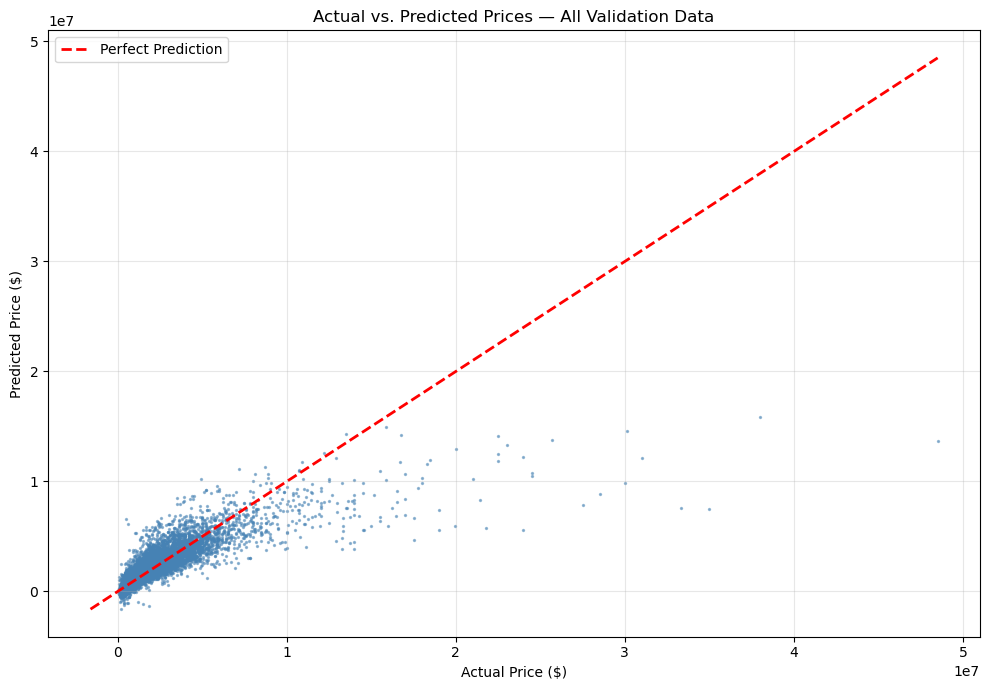

In [21]:
actual = np.asarray(y_val).ravel()
predicted = np.asarray(y_val_pred).ravel()

plt.figure(figsize=(10, 7))

plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

# Perfect prediction line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Prices — All Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

param_dist = {
    "regressor__max_depth": [3, 5, 7, 10, 12, 15, 20, None],
    "regressor__min_samples_split": [2, 5, 10, 15, 20, 30],
    "regressor__min_samples_leaf": [1, 2, 4, 5, 10, 15],
    "regressor__max_features": [None, "sqrt", "log2"],
    "regressor__criterion": ["squared_error", "friedman_mse"],
    "regressor__ccp_alpha": [0.0, 0.001, 0.01, 0.05]
}

random_search = RandomizedSearchCV(
    estimator=dt_model,
    param_distributions=param_dist,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

best_dt_model = random_search.best_estimator_

print("Best Parameters:", random_search.best_params_)
print("Best CV RMSE:", -random_search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'regressor__min_samples_split': 20, 'regressor__min_samples_leaf': 15, 'regressor__max_features': None, 'regressor__max_depth': 12, 'regressor__criterion': 'squared_error', 'regressor__ccp_alpha': 0.0}
Best CV RMSE: 624598.5818333311


In [23]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=15,
        max_features = None,
        criterion = "squared_error",
        ccp_alpha = 0,
        random_state=42
    ))
])

# Fit the model using the original, unencoded data
dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_val_pred = dt_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)


train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

save_results(
    model_name="Decision Tree",
    feature_config="Features A",
    train_report=train_report,
    val_report=val_report
)


TRAINING REPORT
R2: 83.63%
MAE: $215,871.03
RMSE: $538,201.98
Median Absolute Error: $95,707.98
MDAPE: 10.82%

VALIDATION REPORT
R2: 76.40%
MAE: $244,378.70
RMSE: $669,197.55
Median Absolute Error: $103,215.18
MDAPE: 11.53%


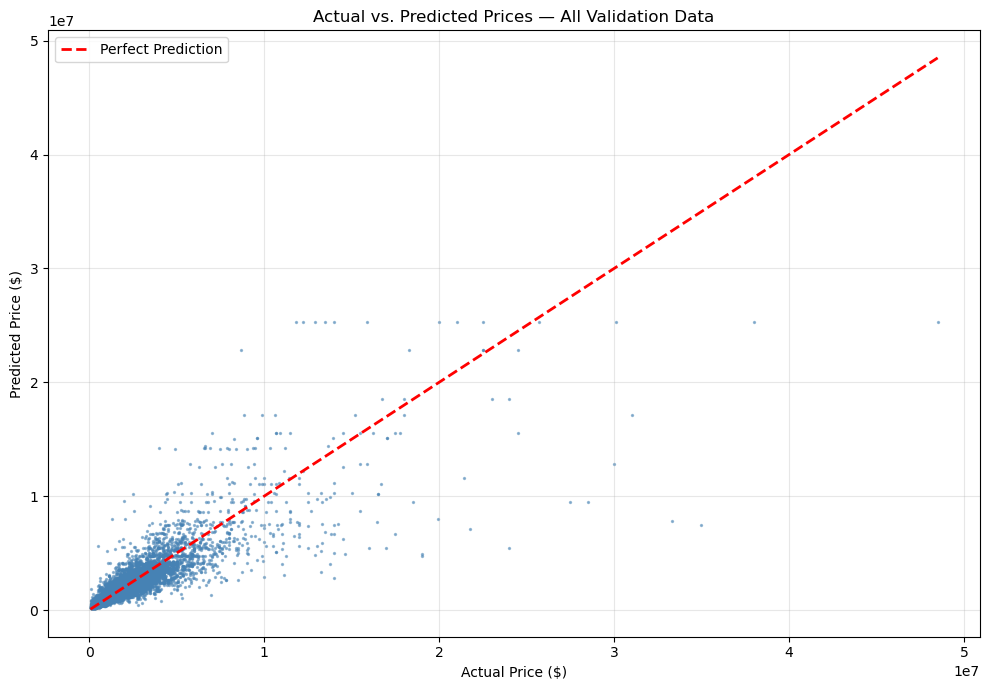

In [24]:
actual = np.asarray(y_val).ravel()
predicted = np.asarray(y_val_pred).ravel()

plt.figure(figsize=(10, 7))

plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

# Perfect prediction line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Prices — All Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=30,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features=0.5,
        bootstrap=True,
        max_samples=0.9,
        random_state=42,
        n_jobs=-1
    ))
])

# Fit the model using the original, unencoded data
rf_model.fit(X_train, y_train)

y_train_pred = rf_model.predict(X_train)
y_val_pred = rf_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)


train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

save_results(
    model_name="Random Forest",
    feature_config="Features A",
    train_report=train_report,
    val_report=val_report
)


TRAINING REPORT
R2: 94.90%
MAE: $96,457.12
RMSE: $300,520.20
Median Absolute Error: $37,173.57
MDAPE: 4.14%

VALIDATION REPORT
R2: 82.68%
MAE: $186,603.40
RMSE: $573,277.64
Median Absolute Error: $72,042.94
MDAPE: 7.99%


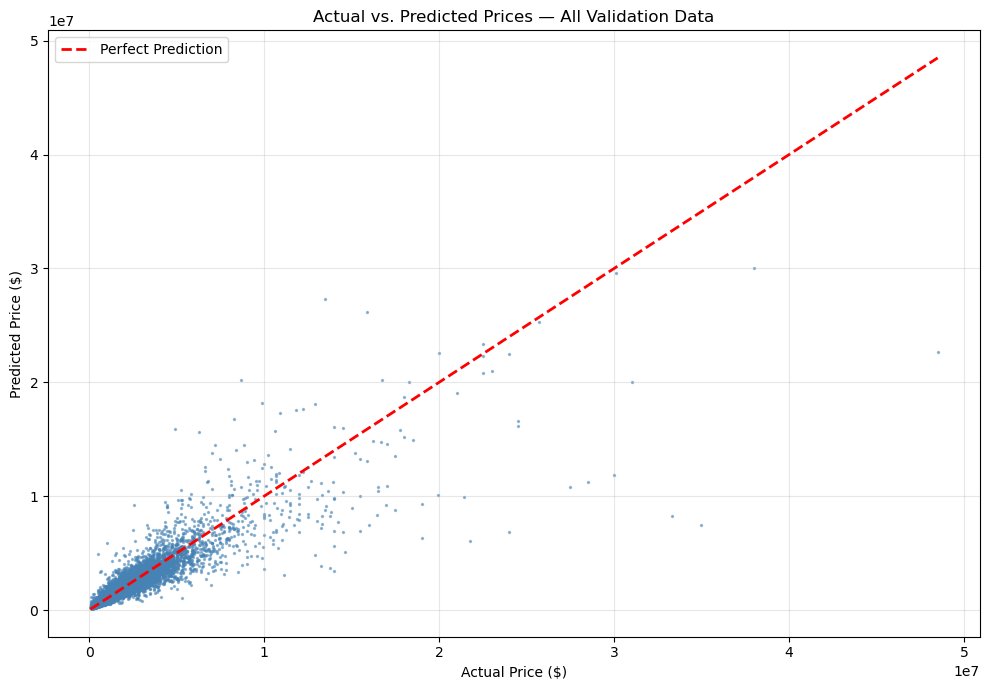

In [26]:
actual = np.asarray(y_val).ravel()
predicted = np.asarray(y_val_pred).ravel()

plt.figure(figsize=(10, 7))

plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

# Perfect prediction line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Prices — All Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Linear Regression has a small training-validation performance gap, suggesting consistent generalization. It has relatively high prediction errors indicating that it might not capture complex relationship between property characteristics and prices.

Decision Tree captures nonlinear patterns and shows improvement in prediction accuracy over Linear Regression, but it is more prone to overfitting since the patterns do not generalize well to unseen properties.

Random Forest provides the strongest overall predictive performance by capturing complex relationships while reducing the instability of an individual tree. The Random Forest achieves the highest validation $R^2$ of 81.05% and lowest validation MAE among the three models. It's main weakness is that the prediction errors are still high. Overall, it offers the best trade-off between predictive accuray and generalization. 

In [27]:
# Create bedroom-bathroom ratio
for data in [X_train, X_val]:
    data["Bed_Bath_Ratio"] = (
        data["BedroomsTotal"] /
        data["BathroomsTotalInteger"].replace(0, np.nan))

# Age of property in years
for data in [X_train, X_val]:
    data["PropertyAge"] = (pd.Timestamp.today().year - data["YearBuilt"])

for data in [X_train, X_val]:
    data["LogLivingArea"] = np.log1p(data["LivingArea"])
    

In [28]:
path_geo = Path("DistrictAreas2526.geojson")
districts = gpd.read_file(path_geo)

def add_school_district(X, districts):
    X=X.copy()
    X["_row_id"] = range(len(X))
    points = gpd.GeoDataFrame(X[["_row_id"]].copy(), geometry=gpd.points_from_xy(
    X["Longitude"],
    X["Latitude"]), crs = "EPSG:4326")

    district_shapes = districts.to_crs("EPSG:4326")

    joined = gpd.sjoin(points, district_shapes[["DistrictName", "geometry"]], how="left", 
                       predicate="within")
    district_map = (joined.drop_duplicates("_row_id").set_index("_row_id")["DistrictName"])
    X["SchoolDistrict"] = X["_row_id"].map(district_map)
    X = X.drop(columns=["_row_id"])
    return X

X_train = add_school_district(X_train, districts)
X_val = add_school_district(X_val, districts)


In [29]:
sqft = pd.to_numeric(X_train_original["LivingArea"], errors="coerce").where(lambda s: s > 0)

y_train_aligned = pd.Series(y_train, index=X_train_original.index)

train_ppsf = y_train_aligned / sqft

train_dates = pd.to_datetime(df_scoped.loc[X_train_original.index, "CloseDate"], errors="coerce")
reference_date = pd.Timestamp("2026-07-31")
close_dates = pd.to_datetime(df_scoped.loc[X_train_original.index, "CloseDate"], errors="coerce")
cutoff_date = reference_date - pd.DateOffset(months=12)
recent_mask = ((close_dates >= cutoff_date) & (close_dates <= reference_date))
train_ppsf = train_ppsf.where(recent_mask)
train_ppsf = train_ppsf.where(np.isfinite(train_ppsf) & (train_ppsf > 0))
feature = "zipcode_median_ppsf"
X_train[feature] = np.nan

kf = KFold(n_splits=5, shuffle=True, random_state=42)
min_zip_samples = 5
for train_idx, val_idx in kf.split(X_train_original):
    X_fold_train = X_train_original.iloc[train_idx]
    X_fold_val = X_train_original.iloc[val_idx]
    ppsf_fold_train = train_ppsf.iloc[train_idx]
    fold_data = pd.DataFrame({
        "PostalCode": X_fold_train["PostalCode"].to_numpy(),
        "PPSF": ppsf_fold_train.to_numpy()}).dropna()

    zip_stats = (fold_data.groupby("PostalCode")["PPSF"].agg(["median", "count"]))
    zip_medians = zip_stats.loc[zip_stats["count"] >= min_zip_samples, "median"]
    global_ppsf_median = fold_data["PPSF"].median()
    encoded = X_fold_val["PostalCode"].map(zip_medians)
    encoded = encoded.fillna(global_ppsf_median)
    X_train.iloc[val_idx, X_train.columns.get_loc(feature)] = encoded.to_numpy()

full_train_data = pd.DataFrame({
    "PostalCode": X_train_original["PostalCode"].to_numpy(),
    "PPSF": train_ppsf.to_numpy()}).dropna()

zip_stats = (full_train_data.groupby("PostalCode")["PPSF"].agg(["median", "count"]))
zip_medians = zip_stats.loc[zip_stats["count"] >= min_zip_samples, "median"]
global_ppsf_median = full_train_data["PPSF"].median()
X_val[feature] = (X_val_original["PostalCode"].map(zip_medians).fillna(global_ppsf_median))

assert X_train[feature].notna().all()
assert X_val[feature].notna().all()

print("Training ZIP PPSF feature created:", X_train[feature].notna().sum())
print("Validation ZIP PPSF feature created:", X_val[feature].notna().sum())
print("Global PPSF median:", round(global_ppsf_median, 2))

Training ZIP PPSF feature created: 157681
Validation ZIP PPSF feature created: 38418
Global PPSF median: 522.51


In [30]:

new_numeric_cols = ["Bed_Bath_Ratio", "PropertyAge", "zipcode_median_ppsf", "LogLivingArea"]

for col in new_numeric_cols:
    if col in X_train.columns and col not in numeric_cols:
        numeric_cols.append(col)

if "SchoolDistrict" in X_train.columns and "SchoolDistrict" not in categorical_cols:
    categorical_cols.append("SchoolDistrict")
    
cols_to_remove = ["YearBuilt", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger"]

X_train = X_train.drop(columns=cols_to_remove, errors="ignore")
X_val = X_val.drop(columns=cols_to_remove, errors="ignore")

numeric_cols_B = [col for col in numeric_cols if col in X_train.columns]

bool_cols_B = [col for col in bool_cols if col in X_train.columns]

categorical_cols_B = [col for col in categorical_cols if col in X_train.columns]

# Print feature lists to verify
display(Markdown("## Features B"))
print("Numeric columns:", numeric_cols_B)
print("Boolean columns:", bool_cols_B)
print("Categorical columns:", categorical_cols_B)


## Features B

Numeric columns: ['Latitude', 'Longitude', 'LotSizeSquareFeet', 'Stories', 'GarageSpaces', 'city_median_price', 'Bed_Bath_Ratio', 'PropertyAge', 'zipcode_median_ppsf', 'LogLivingArea']
Boolean columns: ['NewConstructionYN', 'PoolPrivateYN', 'ViewYN', 'FireplaceYN']
Categorical columns: ['PostalCode', 'CountyOrParish', 'SchoolDistrict']


In [31]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

boolean_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols_B),
    ("boolean", boolean_pipeline, bool_cols_B),
    ("categorical", categorical_pipeline, categorical_cols_B)])

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())])

lr_model.fit(X_train, y_train)

y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)

def mdape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    nonzero = y_true != 0
    if not np.any(nonzero):
        return np.nan
    percentage_errors = (np.abs(y_true[nonzero] - y_pred[nonzero]) / np.abs(y_true[nonzero])) * 100
    return np.median(percentage_errors)

def regression_report(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred) * 100,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedianAbsoluteError": median_absolute_error(y_true, y_pred),
        "MDAPE": mdape(y_true, y_pred)
    }

train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

save_results(
    model_name="Linear Regression",
    feature_config="Features B",
    train_report=train_report,
    val_report=val_report
)


TRAINING REPORT
R2: 67.23%
MAE: $333,520.91
RMSE: $761,433.21
Median Absolute Error: $210,199.87
MDAPE: 21.55%

VALIDATION REPORT
R2: 66.85%
MAE: $340,502.77
RMSE: $793,101.96
Median Absolute Error: $213,445.31
MDAPE: 21.43%


In [32]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=15,
        max_features = None,
        criterion = "squared_error",
        ccp_alpha = 0,
        random_state=42
    ))
])

# Fit the model using the original, unencoded data
dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_val_pred = dt_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)

train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

save_results(
    model_name="Decision Tree",
    feature_config="Features B",
    train_report=train_report,
    val_report=val_report
)


TRAINING REPORT
R2: 85.40%
MAE: $195,509.62
RMSE: $508,326.73
Median Absolute Error: $87,746.90
MDAPE: 9.91%

VALIDATION REPORT
R2: 78.47%
MAE: $226,094.55
RMSE: $639,182.48
Median Absolute Error: $93,358.96
MDAPE: 10.47%


In [33]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=30,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features=0.5,
        bootstrap=True,
        max_samples=0.9,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_train_pred = rf_model.predict(X_train)
y_val_pred = rf_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)

train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

save_results(
    model_name="Random Forest",
    feature_config="Features B",
    train_report=train_report,
    val_report=val_report
)

Exception ignored in: <function ResourceTracker.__del__ at 0x104e69bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1079d5bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104e25bc0>
Traceback (most recent call last


TRAINING REPORT
R2: 95.20%
MAE: $91,956.81
RMSE: $291,313.41
Median Absolute Error: $35,436.69
MDAPE: 3.94%

VALIDATION REPORT
R2: 83.65%
MAE: $182,260.43
RMSE: $557,039.72
Median Absolute Error: $71,004.28
MDAPE: 7.84%


In [34]:
comparison = pd.DataFrame({
    "Feature Type": ["Numeric", "Boolean", "Categorical"],
    "Features A": [
        ", ".join(numeric_cols_A),
        ", ".join(bool_cols_A),
        ", ".join(categorical_cols_A)
    ],
    "Features B": [
        ", ".join(numeric_cols_B),
        ", ".join(bool_cols_B),
        ", ".join(categorical_cols_B)
    ]
})

display(Markdown("## Features A vs Features B"))
display(comparison.style.hide(axis="index"))

## Features A vs Features B

Feature Type,Features A,Features B
Numeric,"LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, Longitude, LotSizeSquareFeet, YearBuilt, Stories, GarageSpaces, city_median_price","Latitude, Longitude, LotSizeSquareFeet, Stories, GarageSpaces, city_median_price, Bed_Bath_Ratio, PropertyAge, zipcode_median_ppsf, LogLivingArea"
Boolean,"NewConstructionYN, PoolPrivateYN, ViewYN, FireplaceYN","NewConstructionYN, PoolPrivateYN, ViewYN, FireplaceYN"
Categorical,"PostalCode, CountyOrParish","PostalCode, CountyOrParish, SchoolDistrict"


In [35]:
results_df = pd.DataFrame(all_results)
display(results_df.style.format(precision=2).hide(axis="index"))

Model,Feature Configuration,Dataset,R2,MAE,RMSE,Median Absolute Error,MDAPE
Linear Regression,Features A,Training,73.43,309821.90,685662.19,192157.42,20.20
Linear Regression,Features A,Validation,72.79,316829.16,718513.00,197709.80,20.26
Decision Tree,Features A,Training,83.63,215871.03,538201.98,95707.98,10.82
Decision Tree,Features A,Validation,76.40,244378.70,669197.55,103215.18,11.53
Random Forest,Features A,Training,94.90,96457.12,300520.20,37173.57,4.14
Random Forest,Features A,Validation,82.68,186603.40,573277.64,72042.94,7.99
Linear Regression,Features B,Training,67.23,333520.91,761433.21,210199.87,21.55
Linear Regression,Features B,Validation,66.85,340502.77,793101.96,213445.31,21.43
Decision Tree,Features B,Training,85.40,195509.62,508326.73,87746.90,9.91
Decision Tree,Features B,Validation,78.47,226094.55,639182.48,93358.96,10.47


The results show that Random Forest performed the best overall on the validation data for both feature sets. With Features B, its $R^2$ increased slightly from 82.68% to 83.65%, and its MAE and RMSE also decreased, meaning its predictions were slightly more accurate. Linear Regression also improved with Features B, while the Decision Tree performed better Features A. The training results were generally better than the validation results, especially for Random Forest, whichi suggests tthe model may be overfitting to some extent. Overall, Features B seems to be a better choice for Linear Regression and Random Forest, while Features A works better for the Decision Tree. 

               Model Feature Configuration     Dataset         R2  \
0  Linear Regression            Features A    Training  73.430747   
1  Linear Regression            Features A  Validation  72.793442   
2      Decision Tree            Features A    Training  83.629968   
3      Decision Tree            Features A  Validation  76.399945   
4      Random Forest            Features A    Training  94.896052   

             MAE           RMSE  Median Absolute Error      MDAPE  
0  309821.901977  685662.188466          192157.423093  20.195074  
1  316829.160485  718512.999548          197709.798786  20.263352  
2  215871.034552  538201.976117           95707.976401  10.824304  
3  244378.696482  669197.546188          103215.181904  11.534921  
4   96457.122613  300520.196654           37173.574287   4.139901  


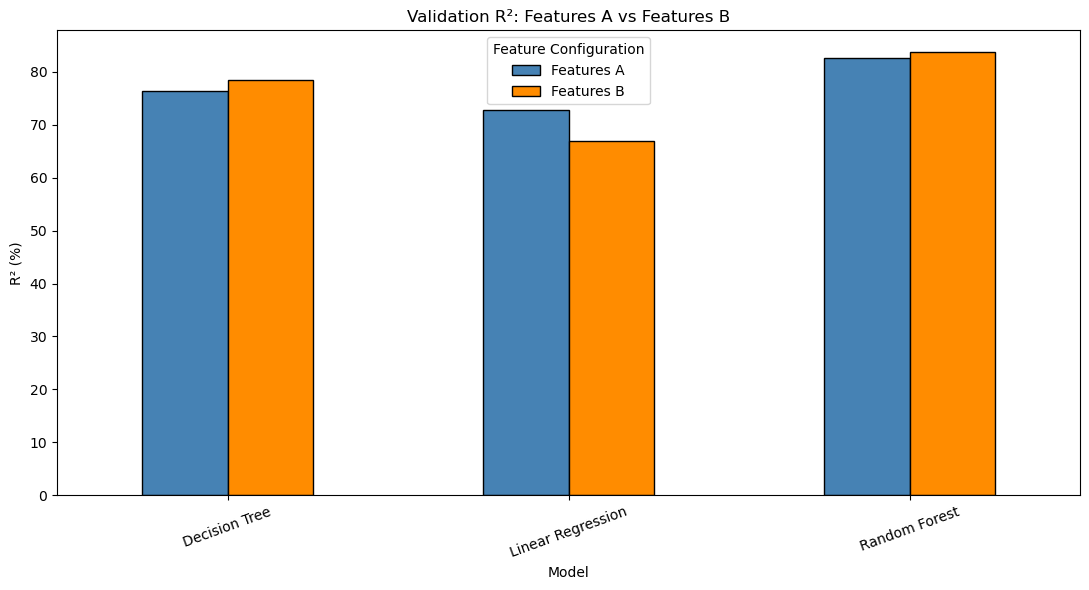

In [36]:
results_df = pd.DataFrame(all_results)

print(results_df.head())

val_results = results_df[results_df["Dataset"] == "Validation"].copy()

r2_pivot = val_results.pivot(index="Model", columns="Feature Configuration", values="R2")

ax = r2_pivot.plot(kind="bar", figsize=(11, 6), color=["steelblue", "darkorange"], edgecolor="black")

ax.set_title("Validation R²: Features A vs Features B")
ax.set_ylabel("R² (%)")
ax.set_xlabel("Model")
ax.legend(title="Feature Configuration")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

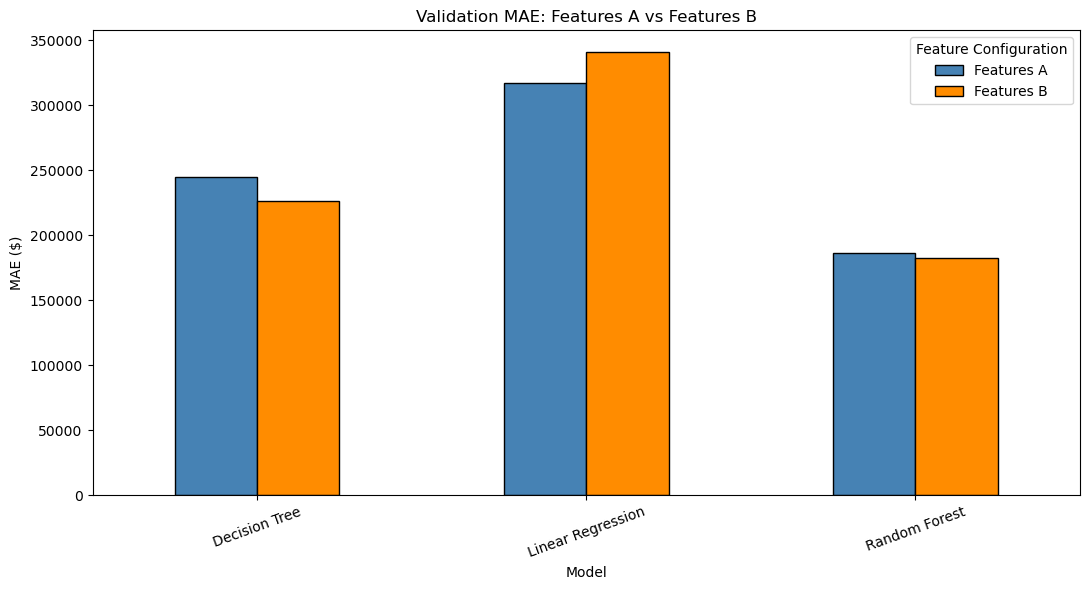

In [37]:
mae_pivot = val_results.pivot(
    index="Model",
    columns="Feature Configuration",
    values="MAE"
)

ax = mae_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "darkorange"],
    edgecolor="black"
)

ax.set_title("Validation MAE: Features A vs Features B")
ax.set_ylabel("MAE ($)")
ax.set_xlabel("Model")
ax.legend(title="Feature Configuration")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

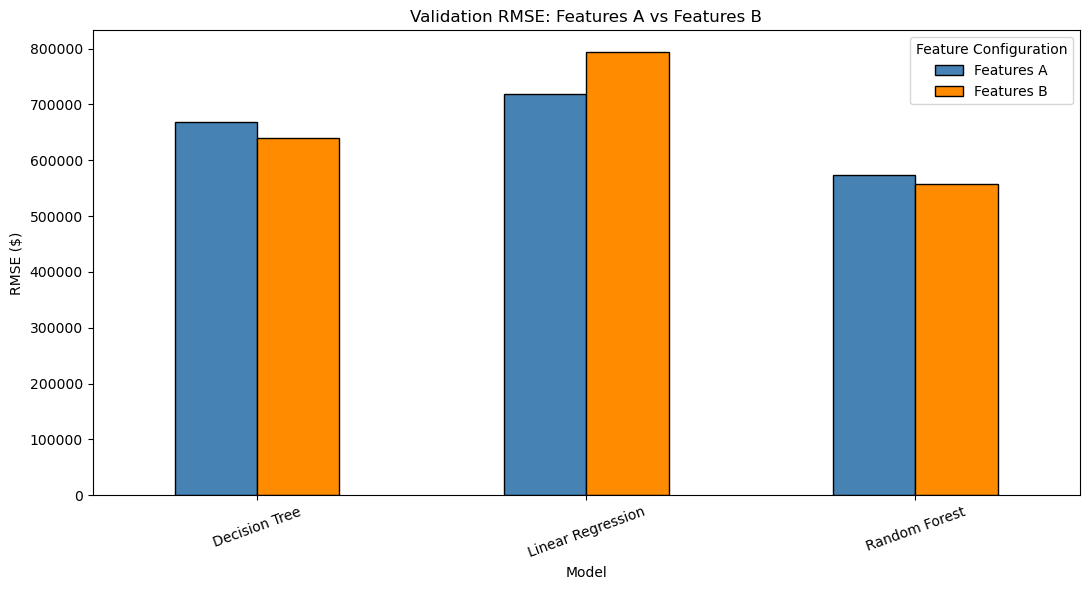

In [38]:
rmse_pivot = val_results.pivot(
    index="Model",
    columns="Feature Configuration",
    values="RMSE"
)

ax = rmse_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "darkorange"],
    edgecolor="black"
)

ax.set_title("Validation RMSE: Features A vs Features B")
ax.set_ylabel("RMSE ($)")
ax.set_xlabel("Model")
ax.legend(title="Feature Configuration")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

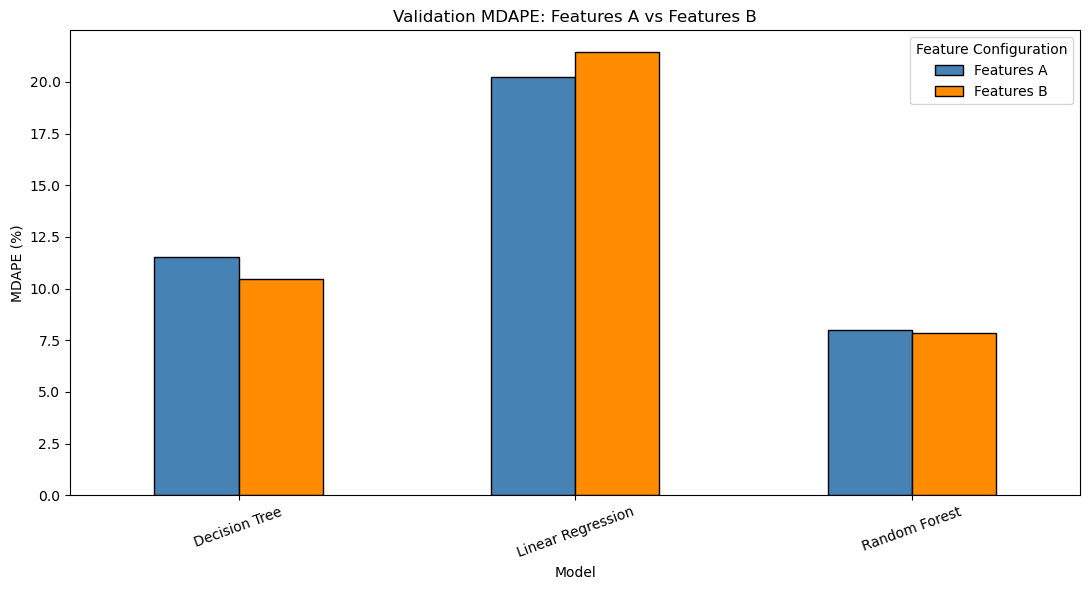

In [39]:
mdape_pivot = val_results.pivot(
    index="Model",
    columns="Feature Configuration",
    values="MDAPE"
)

ax = mdape_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "darkorange"],
    edgecolor="black"
)

ax.set_title("Validation MDAPE: Features A vs Features B")
ax.set_ylabel("MDAPE (%)")
ax.set_xlabel("Model")
ax.legend(title="Feature Configuration")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [40]:
from scipy.stats import randint, uniform, loguniform

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        random_state=42,
        n_jobs=1))])

param_dist = {
    "regressor__n_estimators": randint(350, 701),
    "regressor__max_depth": randint(3, 7),
    "regressor__learning_rate": loguniform(0.06, 0.16),
    "regressor__min_child_weight": randint(2, 9),
    "regressor__subsample": uniform(0.72, 0.26),
    "regressor__colsample_bytree": uniform(0.75, 0.24),
    "regressor__gamma": uniform(0.0, 0.35),
    "regressor__reg_alpha": [0, 0.001, 0.01, 0.1, 1.0],
    "regressor__reg_lambda": [1, 2, 3, 5, 8],
    "regressor__max_delta_step": [0, 1]
}

cv = KFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=cv,    
    refit=True,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=False
)

search.fit(X_train, y_train)

best_xgb_model = search.best_estimator_

print("\nBEST PARAMETERS")
print(search.best_params_)

print("\nBEST CROSS-VALIDATION RMSE")
print(f"${-search.best_score_:,.2f}")


def evaluate_model(model, X, y, label):
    pred = np.asarray(model.predict(X)).ravel()
    y_array = np.asarray(y).ravel()
    rmse = np.sqrt(mean_squared_error(y_array, pred))
    nonzero = y_array != 0
    mdape = (np.median(np.abs((y_array[nonzero] - pred[nonzero]) / y_array[nonzero])) * 100
        if nonzero.any()
        else np.nan)

    print(f"\n{label} REPORT")
    print(f"R2: {r2_score(y_array, pred) * 100:.2f}%")
    print(f"MAE: ${mean_absolute_error(y_array, pred):,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(
        f"Median Absolute Error: "
        f"${median_absolute_error(y_array, pred):,.2f}"
    )
    print(f"MDAPE: {mdape:.2f}%")
    return pred

train_predictions = evaluate_model(best_xgb_model, X_train, y_train, "TRAINING")

val_predictions = evaluate_model(best_xgb_model, X_val, y_val, "VALIDATION")


Fitting 3 folds for each of 10 candidates, totalling 30 fits

BEST PARAMETERS
{'regressor__colsample_bytree': np.float64(0.8448360566404355), 'regressor__gamma': np.float64(0.32433060302782796), 'regressor__learning_rate': np.float64(0.12244650131749613), 'regressor__max_delta_step': 0, 'regressor__max_depth': 6, 'regressor__min_child_weight': 7, 'regressor__n_estimators': 564, 'regressor__reg_alpha': 0.1, 'regressor__reg_lambda': 1, 'regressor__subsample': np.float64(0.9699047263308307)}

BEST CROSS-VALIDATION RMSE
$523,549.14

TRAINING REPORT
R2: 92.76%
MAE: $160,477.28
RMSE: $357,888.75
Median Absolute Error: $78,410.31
MDAPE: 8.84%

VALIDATION REPORT
R2: 83.33%
MAE: $190,453.49
RMSE: $562,369.20
Median Absolute Error: $81,105.19
MDAPE: 9.15%


In [41]:
best_params = search.best_params_

xgb_params = {key.replace("regressor__", ""): value
    for key, value in best_params.items()}

best_xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        **xgb_params,
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        random_state=42,
        n_jobs=-1))])

best_xgb_model.fit(X_train, y_train)

y_train_pred = best_xgb_model.predict(X_train)
y_val_pred = best_xgb_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)

train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")


TRAINING REPORT
R2: 92.76%
MAE: $160,477.28
RMSE: $357,888.75
Median Absolute Error: $78,410.31
MDAPE: 8.84%

VALIDATION REPORT
R2: 83.33%
MAE: $190,453.49
RMSE: $562,369.20
Median Absolute Error: $81,105.19
MDAPE: 9.15%


In [42]:
log_xgb_model = TransformedTargetRegressor(
    regressor=best_xgb_model,
    func=np.log,
    inverse_func=np.exp)

log_xgb_model.fit(X_train, y_train)

train_predictions = evaluate_model(log_xgb_model, X_train, y_train, "TRAINING")

val_predictions = evaluate_model(log_xgb_model, X_val, y_val, "VALIDATION")


TRAINING REPORT
R2: 86.38%
MAE: $172,418.35
RMSE: $490,970.21
Median Absolute Error: $72,196.25
MDAPE: 8.34%

VALIDATION REPORT
R2: 83.25%
MAE: $187,742.34
RMSE: $563,843.96
Median Absolute Error: $75,910.09
MDAPE: 8.66%


In [43]:
for col in categorical_cols:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = pd.Categorical(X_val[col], categories=X_train[col].cat.categories)

lgb_model = lgb.LGBMRegressor(
    objective="regression",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Define hyperparameter search space
param_grid = {
    "max_depth": [5, 7, 10, -1],
    "num_leaves": [15, 31, 40, 50],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "n_estimators": [500, 1000, 1500, 2000],
    "min_child_samples": [20, 30, 40],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 2.0]

}

# Randomized hyperparameter search
random_search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Fit using training data only
random_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)


Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best Parameters:
{'subsample': 0.9, 'reg_lambda': 0.5, 'reg_alpha': 0.5, 'num_leaves': 40, 'n_estimators': 1000, 'min_child_samples': 20, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.9}

Best Cross-Validation RMSE:
521916.11867634807


In [44]:
best_params = random_search.best_params_

best_lgb_model = lgb.LGBMRegressor(
    objective="regression",
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
    **best_params)

best_lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=100, verbose=True),
        lgb.log_evaluation(100)])

y_train_pred_lgb = best_lgb_model.predict(X_train, num_iteration=best_lgb_model.best_iteration_)

y_val_pred_lgb = best_lgb_model.predict(X_val, num_iteration=best_lgb_model.best_iteration_)

train_report = regression_report(y_train, y_train_pred_lgb)
val_report = regression_report(y_val, y_val_pred_lgb)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")

/opt/anaconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's l2: 3.55937e+11
[200]	valid_0's l2: 3.20516e+11
[300]	valid_0's l2: 3.14307e+11
[400]	valid_0's l2: 3.12196e+11
[500]	valid_0's l2: 3.10591e+11
[600]	valid_0's l2: 3.10421e+11
Early stopping, best iteration is:
[566]	valid_0's l2: 3.10065e+11

TRAINING REPORT
R2: 92.84%
MAE: $156,358.75
RMSE: $356,010.39
Median Absolute Error: $73,452.54
MDAPE: 8.30%

VALIDATION REPORT
R2: 83.66%
MAE: $185,210.88
RMSE: $556,834.57
Median Absolute Error: $76,788.80
MDAPE: 8.67%


In [48]:
predictions = {}

predictions["Linear Regression"] = {
    "train": lr_model.predict(X_train),
    "validation": lr_model.predict(X_val)}

predictions["Decision Tree"] = {
    "train": dt_model.predict(X_train),
    "validation": dt_model.predict(X_val)}

predictions["Random Forest"] = {
    "train": rf_model.predict(X_train),
    "validation": rf_model.predict(X_val)}

predictions["XGBoost"] = {
    "train": best_xgb_model.predict(X_train),
    "validation": best_xgb_model.predict(X_val)}

predictions["Log XGBoost"] = {
    "train": log_xgb_model.predict(X_train),
    "validation": log_xgb_model.predict(X_val)}

predictions["LightGBM"] = {
    "train": best_lgb_model.predict(X_train, num_iteration=best_lgb_model.best_iteration_),
    "validation": best_lgb_model.predict(X_val, num_iteration=best_lgb_model.best_iteration_)}

In [49]:
all_results = []

for name, pred in predictions.items():
    train_report = regression_report(y_train, pred["train"])
    val_report = regression_report(y_val, pred["validation"])
    all_results.append({
        "Model": name,
        "Training R2": train_report["R2"],
        "Validation R2": val_report["R2"],
        "Training MAE": train_report["MAE"],
        "Validation MAE": val_report["MAE"],
        "Training RMSE": train_report["RMSE"],
        "Validation RMSE": val_report["RMSE"],
        "Validation Median AE": val_report["MedianAbsoluteError"],
        "Validation MDAPE": val_report["MDAPE"]})

results_df = pd.DataFrame(all_results)

display(results_df.style.format(precision=2).hide(axis="index"))

Model,Training R2,Validation R2,Training MAE,Validation MAE,Training RMSE,Validation RMSE,Validation Median AE,Validation MDAPE
Linear Regression,67.23,66.83,333520.91,340687.14,761433.21,793354.80,213488.96,21.43
Decision Tree,85.40,78.47,195509.62,226094.55,508326.73,639182.48,93358.96,10.47
Random Forest,95.20,83.65,91956.81,182260.43,291313.41,557039.72,71004.28,7.84
XGBoost,92.76,83.33,160477.28,190508.97,357888.75,562396.65,81116.06,9.15
Log XGBoost,86.38,83.25,172418.35,187749.84,490970.21,563847.08,75923.72,8.66
LightGBM,92.84,83.66,156358.75,185210.88,356010.39,556834.57,76788.80,8.67


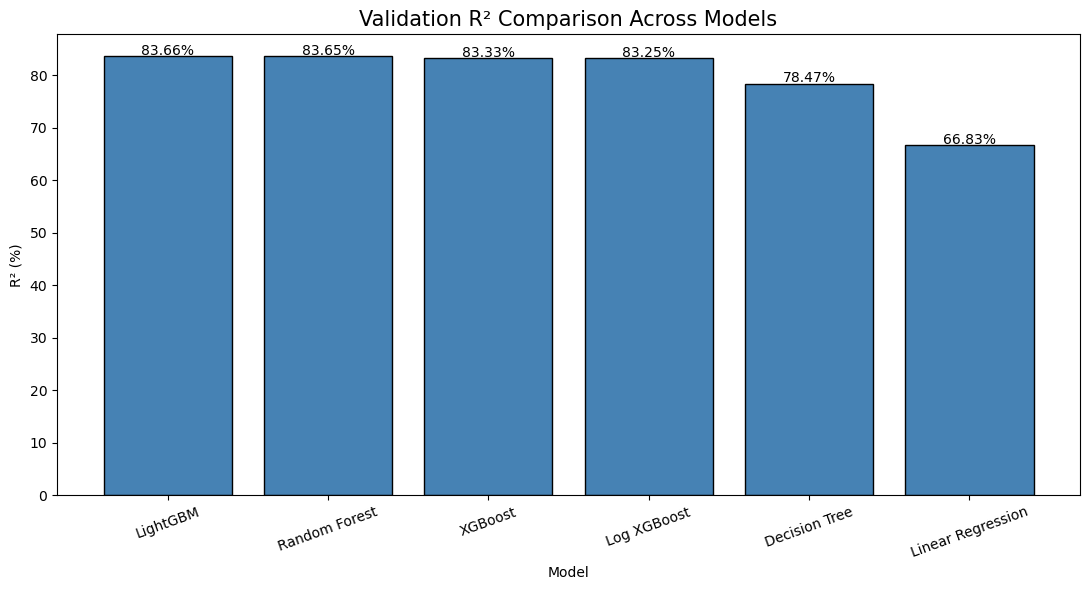

In [50]:
data = results_df.sort_values(
    "Validation R2", ascending=False)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    data["Model"],
    data["Validation R2"],
    color="steelblue",
    edgecolor="black")

plt.title("Validation R² Comparison Across Models", fontsize=15)
plt.ylabel("R² (%)")
plt.xlabel("Model")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.2,
        f"{bar.get_height():.2f}%",
        ha="center",
        fontsize=10)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

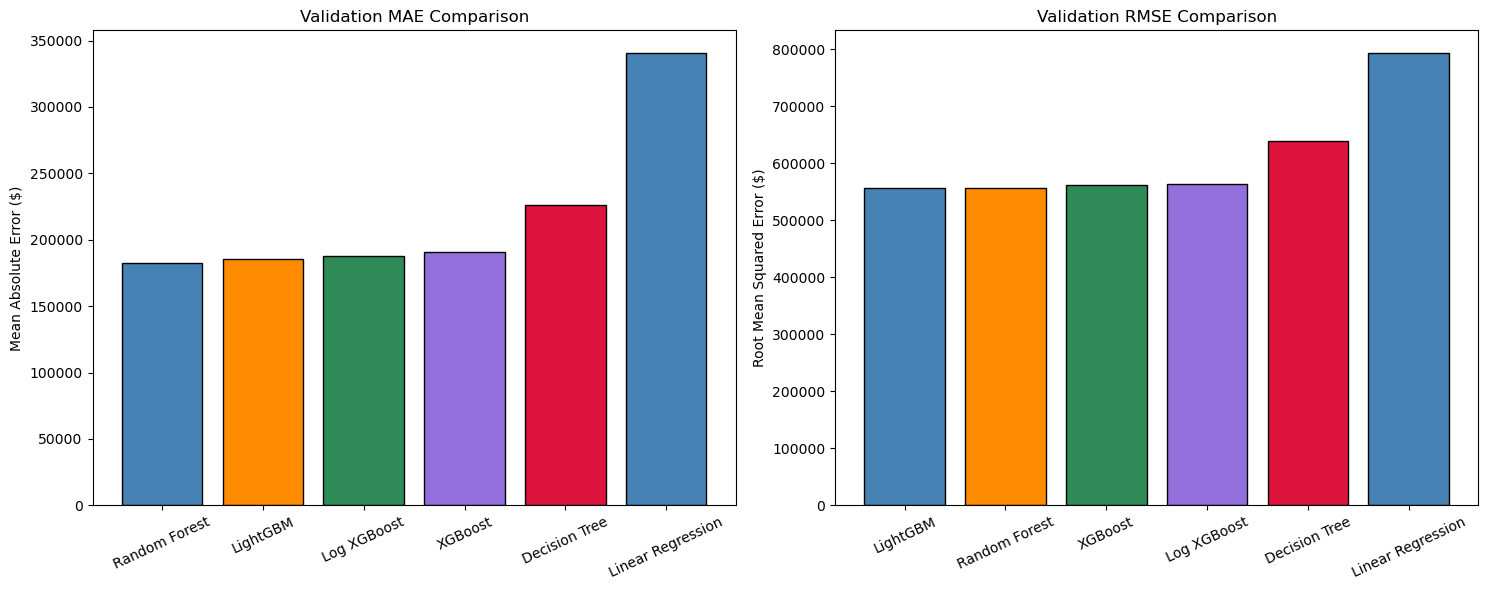

In [51]:
colors = [
    "steelblue",
    "darkorange",
    "seagreen",
    "mediumpurple",
    "crimson"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

mae_data = results_df.sort_values("Validation MAE")

axes[0].bar(
    mae_data["Model"],
    mae_data["Validation MAE"],
    color=colors,
    edgecolor="black")

axes[0].set_title("Validation MAE Comparison")
axes[0].set_ylabel("Mean Absolute Error ($)")
axes[0].tick_params(axis="x", rotation=25)

rmse_data = results_df.sort_values("Validation RMSE")

axes[1].bar(
    rmse_data["Model"],
    rmse_data["Validation RMSE"],
    color=colors,
    edgecolor="black")

axes[1].set_title("Validation RMSE Comparison")
axes[1].set_ylabel("Root Mean Squared Error ($)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

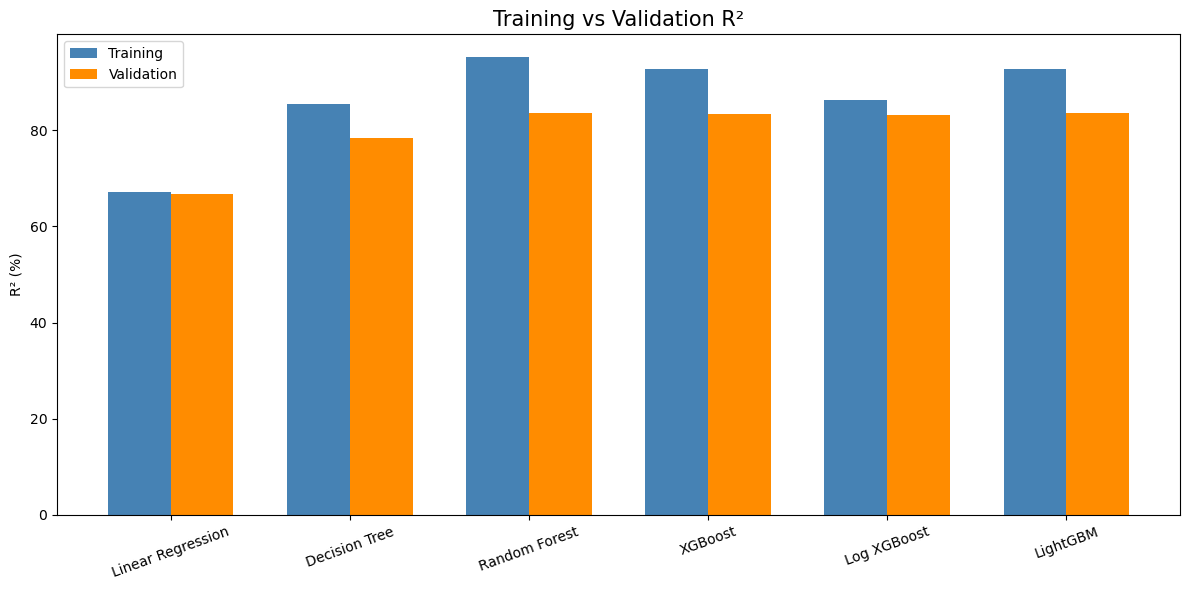

In [52]:
x = np.arange(len(results_df))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width/2,
    results_df["Training R2"],
    width,
    label="Training",
    color="steelblue")

ax.bar(
    x + width/2,
    results_df["Validation R2"],
    width,
    label="Validation",
    color="darkorange")

ax.set_title("Training vs Validation R²", fontsize=15)
ax.set_ylabel("R² (%)")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=20)

ax.legend()

plt.tight_layout()
plt.show()

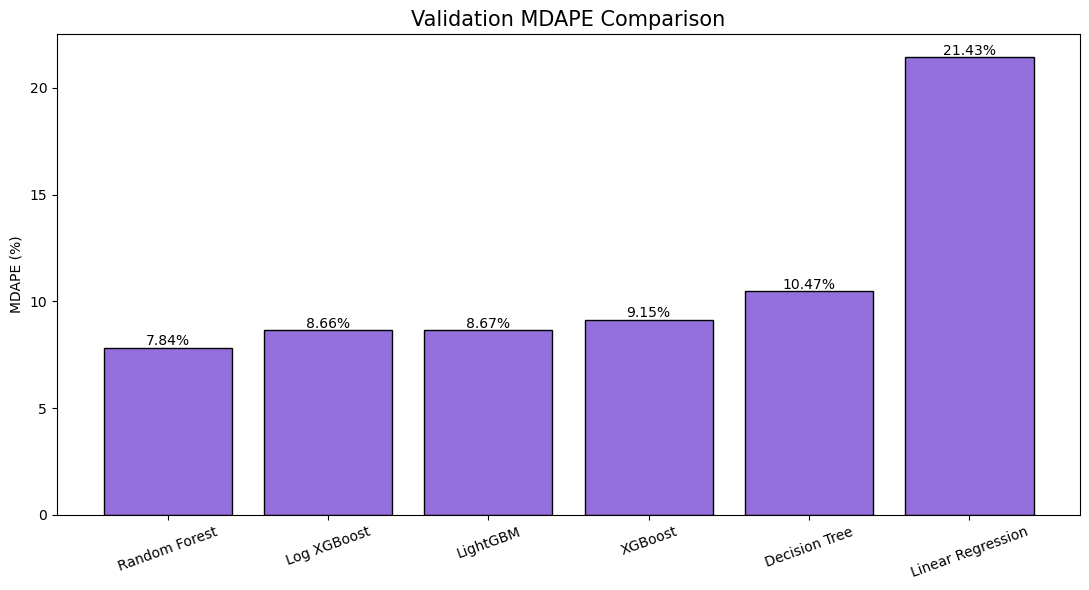

In [53]:
data = results_df.sort_values(
    "Validation MDAPE")

plt.figure(figsize=(11, 6))

bars = plt.bar(
    data["Model"],
    data["Validation MDAPE"],
    color="mediumpurple",
    edgecolor="black")

plt.title("Validation MDAPE Comparison", fontsize=15)
plt.ylabel("MDAPE (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f"{bar.get_height():.2f}%",
        ha="center")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

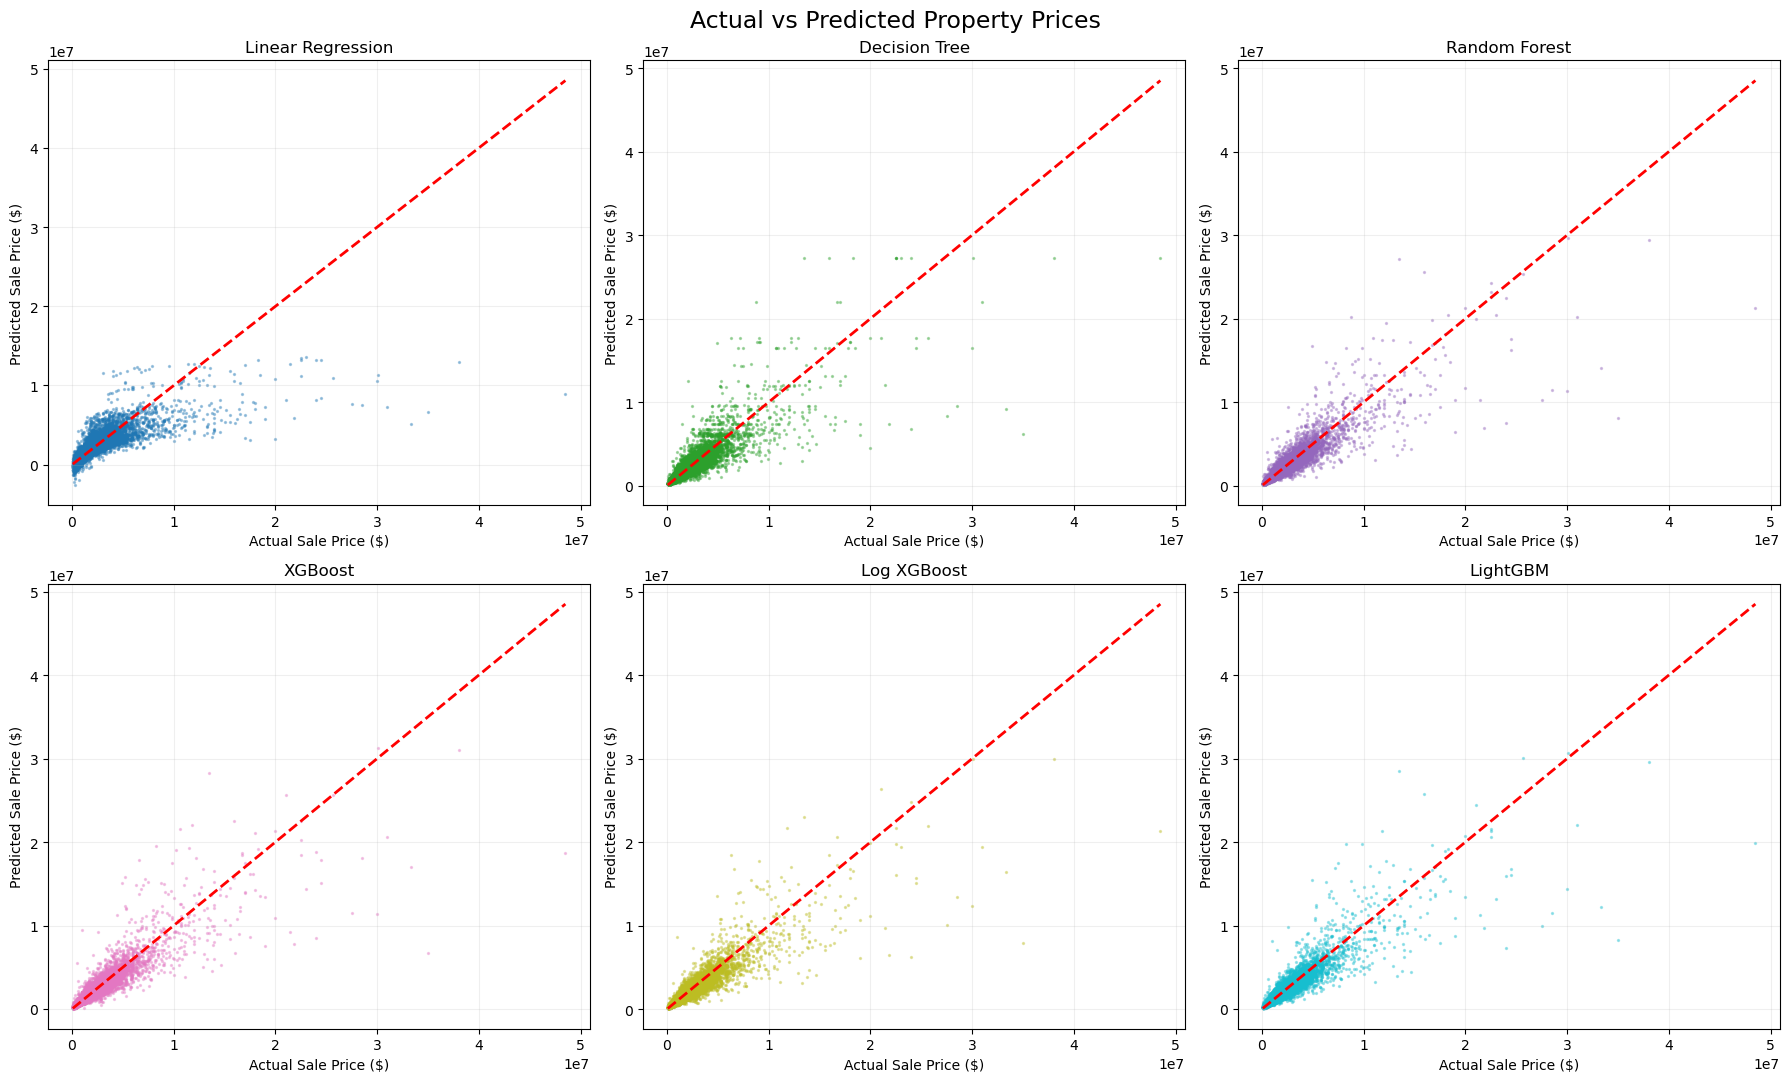

In [54]:
actual = np.asarray(y_val).ravel()

n_models = len(predictions)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

axes = axes.flatten()

colors = plt.cm.tab10(np.linspace(0, 1, n_models))

min_value = actual.min()
max_value = actual.max()

for i, (name, pred) in enumerate(predictions.items()):
    predicted = np.asarray(pred["validation"]).ravel()
    axes[i].scatter(
        actual,
        predicted,
        alpha=0.35,
        s=2,
        color=colors[i])

    axes[i].plot(
        [min_value, max_value],
        [min_value, max_value],
        "r--",
        linewidth=2)

    axes[i].set_title(name)
    axes[i].set_xlabel("Actual Sale Price ($)")
    axes[i].set_ylabel("Predicted Sale Price ($)")
    axes[i].grid(alpha=0.2)

for j in range(n_models, len(axes)):
    axes[j].axis("off")

fig.suptitle(
    "Actual vs Predicted Property Prices",
    fontsize=17)

plt.tight_layout()
plt.show()

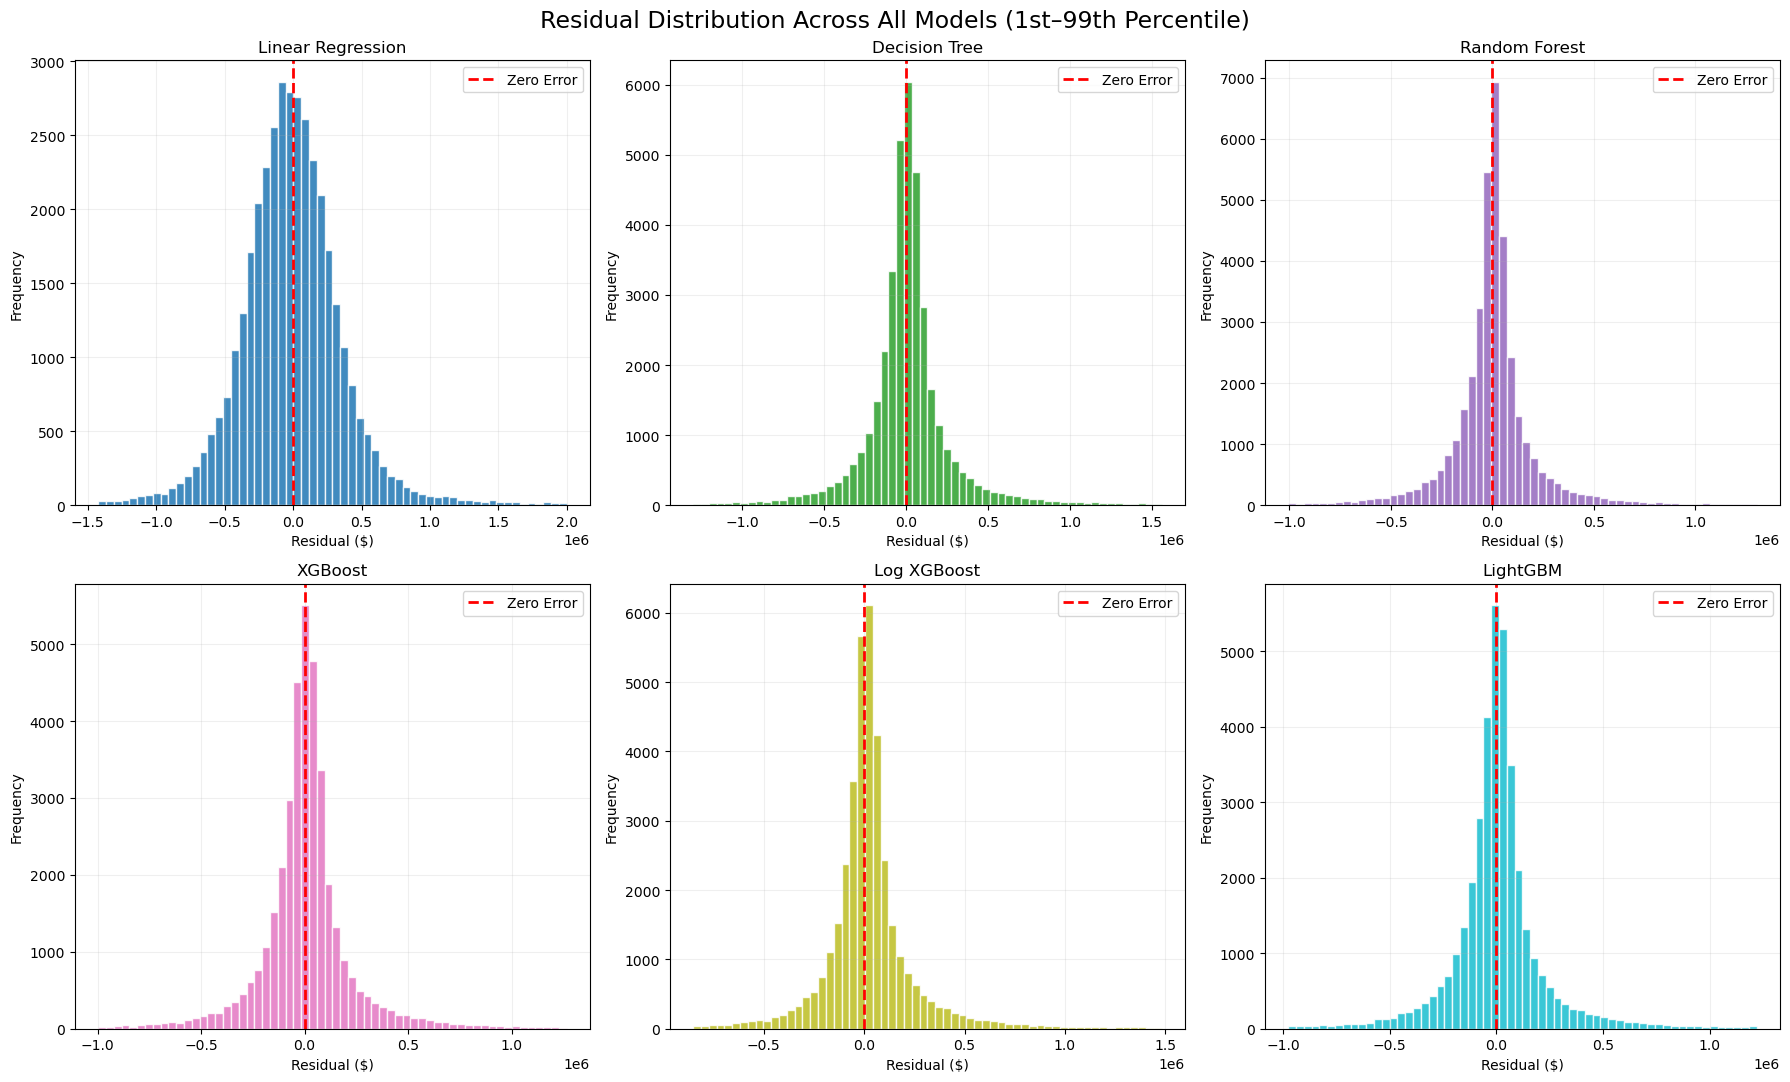

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

n_models = len(predictions)

for i, (name, pred) in enumerate(predictions.items()):
    residuals = (actual - np.asarray(pred["validation"]).ravel())
    residuals = residuals[np.isfinite(residuals)]
    lower = np.percentile(residuals, 1)
    upper = np.percentile(residuals, 99)

    axes[i].hist(
        residuals,
        bins=60,
        range=(lower, upper),
        color=colors[i],
        edgecolor="white",
        alpha=0.85)

    axes[i].axvline(
        0,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Zero Error")

    axes[i].set_title(name)
    axes[i].set_xlabel("Residual ($)")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()
    axes[i].grid(alpha=0.2)

for j in range(n_models, len(axes)):
    axes[j].axis("off")

fig.suptitle(
    "Residual Distribution Across All Models (1st–99th Percentile)",
    fontsize=17)

plt.tight_layout()
plt.show()

In [56]:
ranked_models = results_df.sort_values(
    "Validation MAE",
    ascending=True).reset_index(drop=True)

display(
    ranked_models[
        [
            "Model",
            "Validation R2",
            "Validation MAE",
            "Validation RMSE",
            "Validation Median AE",
            "Validation MDAPE"]].round(2))

print("\nBest model by validation MAE:")
print(ranked_models.iloc[0]["Model"])

print("\nBest model by validation R2:")
print(
    results_df.loc[
        results_df["Validation R2"].idxmax(),
        "Model"])

,Model,Validation R2,Validation MAE,Validation RMSE,Validation Median AE,Validation MDAPE
0,Random Forest,83.65,182260.43,557039.72,71004.28,7.84
1,LightGBM,83.66,185210.88,556834.57,76788.80,8.67
2,Log XGBoost,83.25,187749.84,563847.08,75923.72,8.66
3,XGBoost,83.33,190508.97,562396.65,81116.06,9.15
4,Decision Tree,78.47,226094.55,639182.48,93358.96,10.47
5,Linear Regression,66.83,340687.14,793354.80,213488.96,21.43



Best model by validation MAE:
Random Forest

Best model by validation R2:
LightGBM


The Random Forest, LightGBM, and XGBoost are performing very similarly, with all three achieveing validation $R^2$ scores above 83%. LightGBM achieved the highest $R^2$, suggesting that Light GBM explains slightly more variation in housing prices. Random Forest produced the lowest MAE, Median Error, and MDAPE among all the models. This means that its absolute prediction errors were smallar than those of the other models. XGBoost models performed relatively close to Random Forest and LightGBM suggesting that Gradient Boosting is also effective for capturing nonlinear relationship in housing prices. But neither XGBoost nor LightGBM outperformed Random Forest across the main error metrics. Decision Tree and Linear Regression performed worse. 